# M1-B1 — Modélisation

Tâches 4 à 8. Le pipeline et les variables sont dans `model/features.py`, le chargement, le découpage, l'évaluation et le choix du seuil dans `train.py` :
ce notebook les réutilise pour ne pas dupliquer le code.

In [1]:
import os
import sys
import tempfile
import time
import warnings
from pathlib import Path

import joblib
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
load_dotenv(ROOT / ".env")
warnings.filterwarnings("ignore")

engine = create_engine(os.environ["DATABASE_URL"])

from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV, StratifiedKFold, TimeSeriesSplit, cross_validate

import train as T
from model import features as F
from model.train_baseline import FEATURES as V1_FEATURES, build_pipeline as build_v1

INPUT_FEATURES = F.RAW_FEATURES   # colonnes brutes données à la v2 (colonnes de fuite exclues)
N_JOBS = 1                        # calcul séquentiel : la mémoire de la machine est limitée

df = T.load_data(engine)
train, test = T.split_train_test(df)
y_train, y_test = train["is_canceled"], test["is_canceled"]

## Tâche 4 — Un premier modèle

Toutes les colonnes, encodage sommaire, dates laissées de côté.

In [2]:
X_naif = pd.get_dummies(
    train.drop(columns=["is_canceled", "arrival_date", "reservation_status_date", "reservation_id"]),
    dtype=int,
).fillna(0)
rf = RandomForestClassifier(n_estimators=50, n_jobs=-1, random_state=0)
cross_validate(rf, X_naif, y_train, cv=3, scoring="accuracy")["test_score"]


array([1., 1., 1.])

In [3]:
rf.fit(X_naif, y_train)
pd.Series(rf.feature_importances_, X_naif.columns).sort_values(ascending=False).head(5)


reservation_status_Check-Out    0.417759
reservation_status_Canceled     0.264817
deposit_type_No Deposit         0.059809
deposit_type_Non Refund         0.054535
country_PRT                     0.028015
dtype: float64

**Diagnostic.** `reservation_status` est le *dernier* statut de la réservation (`Canceled`, `Check-Out`, `No-Show`) : c'est la réponse elle-même, connue **après** l'événement à prédire. Même raisonnement pour :

- `reservation_status_date` : la date de ce dernier statut ;
- `assigned_room_type` : la chambre attribuée à l'arrivée ;
- `booking_changes` : nombre de modifications, qui peut être mis à jour après la réservation : exclue par prudence ;
- `required_car_parking_spaces` : aucune annulation parmi les réservations avec parking, saisie présumée à l'arrivée : exclue par prudence ;
- `days_in_waiting_list` et `agent`/`company` sont connus à la réservation : pas de fuite.

Ces colonnes sont listées dans `model/features.py` (`COLONNES_FUITE`) et ne font pas partie de `INPUT_FEATURES`.

## Tâche 5 — Reproduire la v1 (référence à battre)

In [ ]:
tss = TimeSeriesSplit(n_splits=5)
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
SCORING = ["f1", "precision", "recall"]
X_v1 = train[V1_FEATURES]


def resume(nom, pipeline, X, cv=tss):
    """Validation croisée : F1 moyen et écart-type, F1 d'entraînement, précision et rappel."""
    r = pd.DataFrame(
        cross_validate(pipeline, 
                       X, y_train, 
                       cv=cv, scoring=SCORING,
                       return_train_score=True, 
                       n_jobs=N_JOBS)
        )
    return pd.Series({
        "F1 validation": r["test_f1"].mean(),
        "écart-type": r["test_f1"].std(),
        "F1 entraînement": r["train_f1"].mean(),
        "précision": r["test_precision"].mean(),
        "rappel": r["test_recall"].mean(),
    }, name=nom).round(3)


# Étape 1 : validation croisée sur 5 folds
etape1 = pd.DataFrame(
    cross_validate(
        build_v1(), X_v1, y_train, 
        cv=kfold, scoring=SCORING,
        return_train_score=True, n_jobs=N_JOBS)
        )
display(etape1[["test_f1", "test_precision", "test_recall"]].agg(["mean", "std"]).round(3))

# Étape 2 : écart entre entraînement et validation
print(f"F1 entraînement {etape1['train_f1'].mean():.3f} | F1 validation {etape1['test_f1'].mean():.3f} "
      f"| écart {etape1['train_f1'].mean() - etape1['test_f1'].mean():.3f}")

# Étape 3 : mini-recherche sur max_iter et learning_rate
recherche_v1 = GridSearchCV(build_v1(),
                            {"classifier__max_iter": [100, 200], "classifier__learning_rate": [0.05, 0.1]},
                            cv=kfold, scoring="f1", n_jobs=N_JOBS)
recherche_v1.fit(X_v1, y_train)
display(pd.DataFrame(recherche_v1.cv_results_)[
    ["param_classifier__max_iter", "param_classifier__learning_rate", "mean_test_score", "std_test_score"]
].round(3))

# Étape 4 : validation temporelle (données triées par date)
# Les scores baissent : chaque fold valide sur une période future.
ref_v1 = resume("v1", build_v1(), X_v1, cv=tss)
ref_v1.to_frame()

,test_f1,test_precision,test_recall
mean,0.850,0.882,0.820
std,0.003,0.002,0.005


F1 entraînement 0.872 | F1 validation 0.850 | écart 0.022


,param_classifier__max_iter,param_classifier__learning_rate,mean_test_score,std_test_score
0,100,0.05,0.837,0.004
1,200,0.05,0.843,0.004
2,100,0.10,0.845,0.004
3,200,0.10,0.850,0.003


,v1
F1 validation,0.701
écart-type,0.169
F1 entraînement,0.924
précision,0.853
rappel,0.613


## Tâche 6 — Pipeline et variables

Les variables calculées sont dans `features.py` (fonction nommée, importable par l'API).
Comparaison de trois modèles, avec les mêmes variables.

In [5]:
modeles = {
    "régression logistique": F.build_pipeline(LogisticRegression(max_iter=2000), scale=True),
    "forêt aléatoire": F.build_pipeline(RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=1)),
    "gradient boosting": F.build_pipeline(HistGradientBoostingClassifier(random_state=42)),
}

In [3]:
# Nouvelles variables calculées par le pipeline (5 premières réservations)
F.ajouter_variables(train)[F.NEW_NUMERICAL].head().T

,0,1,2,3,4
total_nights,2.0,4.00,4.0,6.00,2.00
total_guests,1.0,2.00,1.0,2.00,2.00
has_children,0.0,0.00,0.0,0.00,0.00
adr_per_guest,0.0,38.25,68.0,38.25,50.75
total_price,0.0,306.00,272.0,459.00,203.00
has_special_request,0.0,1.00,1.0,1.00,0.00
has_previous_cancel,0.0,0.00,0.0,0.00,1.00
has_company,0.0,0.00,0.0,0.00,0.00
arrival_month,7.0,7.00,7.0,7.00,7.00
arrival_weekday,2.0,2.00,2.0,2.00,2.00


In [6]:
comparaison = pd.DataFrame(
    [ref_v1] + [resume(f"v2 {nom}", p, train[INPUT_FEATURES]) for nom, p in modeles.items()]
)
comparaison

,F1 validation,écart-type,F1 entraînement,précision,rappel
v1,0.701,0.169,0.924,0.853,0.613
v2 régression logistique,0.687,0.096,0.800,0.818,0.595
v2 forêt aléatoire,0.721,0.122,0.988,0.893,0.614
v2 gradient boosting,0.711,0.166,0.909,0.854,0.629


## Tâche 7 — Valider et régler

D'abord avec une validation croisée **aléatoire**, puis **temporelle**

In [7]:
# Même forêt, deux façons de la valider
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # folds tirés au hasard
foret = modeles["forêt aléatoire"]
pd.DataFrame([
    resume("forêt, validation aléatoire", foret, train[INPUT_FEATURES], cv=kfold),
    resume("forêt, validation temporelle", foret, train[INPUT_FEATURES], cv=tss),   # folds dans le temps
])

,F1 validation,écart-type,F1 entraînement,précision,rappel
"forêt, validation aléatoire",0.868,0.003,0.992,0.908,0.832
"forêt, validation temporelle",0.721,0.122,0.988,0.893,0.614


In [ ]:
# Tester toutes les combinaisons de réglages (3 x 3 = 9), en validation temporelle
recherche = GridSearchCV(
    F.build_pipeline(RandomForestClassifier(n_estimators=200, max_features="sqrt", random_state=42, n_jobs=1)),
    {"classifier__max_depth": [10, 20, None], "classifier__min_samples_leaf": [1, 5, 20]},   # valeurs testées
    cv=tss, scoring="f1", return_train_score=True, n_jobs=N_JOBS,   # garder aussi le score d'entraînement
)
recherche.fit(train[INPUT_FEATURES], y_train)

# Tableau des résultats : réglages, F1 entraînement, F1 validation, écart-type
trace = pd.DataFrame(recherche.cv_results_)[
    ["param_classifier__max_depth", "param_classifier__min_samples_leaf",
     "mean_train_score", "mean_test_score", "std_test_score"]
]
trace["écart"] = trace["mean_train_score"] - trace["mean_test_score"]   # mesure du surapprentissage
trace.to_csv(ROOT / "notebooks" / "traces" / "grille_foret_f1.csv", index=False)   # trace sauvegardée

# Règle de choix : parmi les réglages à moins de 0,01 du meilleur F1 de validation,
# celui dont l'écart entraînement - validation est le plus faible.
proches = trace[trace["mean_test_score"] >= trace["mean_test_score"].max() - 0.01]
retenu = proches.loc[proches["écart"].idxmin()]

# Réglages finaux de la forêt, réutilisés en tâche 8
best_params = {"n_estimators": 200, "max_features": "sqrt",
               "max_depth": retenu["param_classifier__max_depth"],
               "min_samples_leaf": int(retenu["param_classifier__min_samples_leaf"])}
print(best_params)

# du meilleur au moins bon
trace.sort_values("mean_test_score", ascending=False).round(3)  

{'n_estimators': 200, 'max_features': 'sqrt', 'max_depth': 20, 'min_samples_leaf': 5}


,param_classifier__max_depth,param_classifier__min_samples_leaf,mean_train_score,mean_test_score,std_test_score,écart
3,20,1,0.952,0.725,0.102,0.226
6,None,1,0.988,0.721,0.109,0.267
7,None,5,0.899,0.717,0.101,0.181
4,20,5,0.891,0.717,0.100,0.174
8,None,20,0.859,0.695,0.111,0.165
5,20,20,0.857,0.690,0.117,0.167
0,10,1,0.798,0.614,0.161,0.184
1,10,5,0.791,0.607,0.170,0.183
2,10,20,0.781,0.606,0.166,0.176


**Choix du modèle.** La validation aléatoire surestime le F1 (0,868 contre 0,721) : ses plis partagent les mêmes périodes que l'entraînement. La validation temporelle, cohérente avec le jeu de test, est retenue.

La forêt aléatoire obtient le meilleur F1 en validation temporelle, mais surapprend avec ses réglages par défaut (0,988 en entraînement). Parmi les réglages à moins de 0,01 du meilleur F1, celui qui a le plus faible écart entraînement - validation est retenu : `max_depth=20`, `min_samples_leaf=5`, 200 arbres, `max_features="sqrt"`. Il obtient 0,717 en validation, contre 0,725 pour le meilleur, avec un écart ramené de 0,226 à 0,174. Des contraintes plus fortes font baisser la validation. Trace : `notebooks/traces/grille_foret_f1.csv`.

## Tâche 8 — Le verdict

### Les deux erreurs possibles du modèle

| Erreur | Ce qui se passe | Coût pour l'hôtel |
|---|---|---|
| Annulation ratée (faux négatif) | Le modèle dit « le client viendra », mais il annule. La chambre reste vide. | Une nuit non vendue. C'est le problème signalé par le service réservations. |
| Fausse alerte (faux positif) | Le modèle dit « le client va annuler », mais il vient. | Dépend de ce que fait l'hôtel : s'il revend la chambre, il doit reloger ce client ailleurs (coût élevé) ; s'il se contente de le relancer, le coût est faible. |

### La métrique choisie

Le F1, qui équilibre les deux erreurs. On surveille en plus le rappel (la part des annulations détectées), car c'est le point faible de la v1.

### Le seuil de décision

Le modèle donne une probabilité d'annulation. Le seuil fixe à partir de quelle probabilité on annonce une annulation. Il est choisi sur les 4 derniers mois de l'entraînement, jamais sur le jeu de test.

In [9]:
# Choisir le seuil sur les 4 derniers mois de l'entraînement (le test n'est pas utilisé)
seuil, trace_seuil = T.choose_threshold(train, best_params)
print("seuil retenu :", seuil)
trace_seuil.round(3)   # F1, précision et rappel pour chaque seuil essayé

seuil retenu : 0.3


,seuil,f1,precision,recall
0,0.20,0.726,0.637,0.843
1,0.25,0.740,0.705,0.778
2,0.30,0.743,0.753,0.732
3,0.35,0.734,0.794,0.682
4,0.40,0.711,0.836,0.619
5,0.45,0.680,0.875,0.556
6,0.50,0.634,0.909,0.487
7,0.55,0.581,0.946,0.419
8,0.60,0.537,0.979,0.370
9,0.65,0.509,0.991,0.342


In [ ]:
# Les trois modèles à comparer
v1 = build_v1()                                    # recette v1, seuil 0,5 par défaut
v2_05 = T.build_pipeline(best_params, 0.5)         # v2 au seuil par défaut
v2 = T.build_pipeline(best_params, seuil)          # v2 au seuil choisi

verdict = {}
for nom, modele, colonnes in [("v1", v1, V1_FEATURES),
                              ("v2, seuil 0,5", v2_05, INPUT_FEATURES),
                              (f"v2, seuil {seuil}", v2, INPUT_FEATURES)]:
    
    # Entraîner sur tout le jeu d'entraînement, en mesurant la durée
    debut = time.perf_counter()
    modele.fit(train[colonnes], y_train)
    duree = time.perf_counter() - debut

    # Mesurer la taille du modèle en le sauvegardant dans un dossier temporaire
    with tempfile.TemporaryDirectory() as dossier:
        chemin = Path(dossier) / "modele.joblib"
        joblib.dump(modele, chemin)
        taille = chemin.stat().st_size / 1e6
        
    # Évaluer une seule fois sur le jeu de test
    m = T.evaluate(modele, test[colonnes], y_test)
    verdict[nom] = {"f1": m["f1"], "precision": m["precision"], "recall": m["recall"],
                    "roc_auc": m["roc_auc"], "temps d'entraînement (s)": round(duree, 1),
                    "taille (Mo)": round(taille, 1)}
pd.DataFrame(verdict)   # une colonne par modèle

,v1,"v2, seuil 0,5","v2, seuil 0.3"
f1,0.5752,0.5415,0.7263
precision,0.9235,0.9713,0.8688
recall,0.4177,0.3754,0.6239
roc_auc,0.8669,0.8959,0.8959
temps d'entraînement (s),5.2000,9.2000,9.2000
taille (Mo),0.7000,32.9000,32.9000


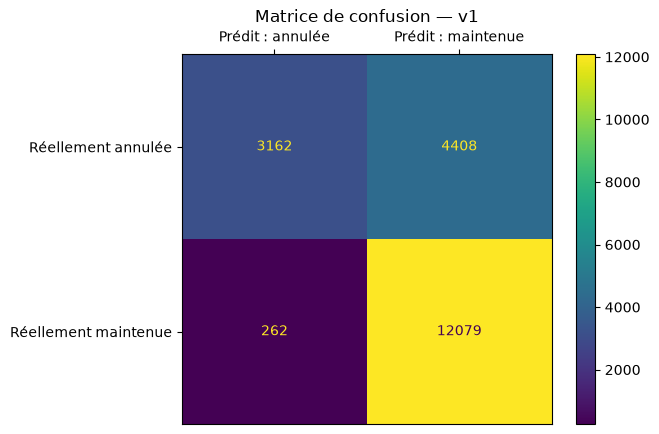

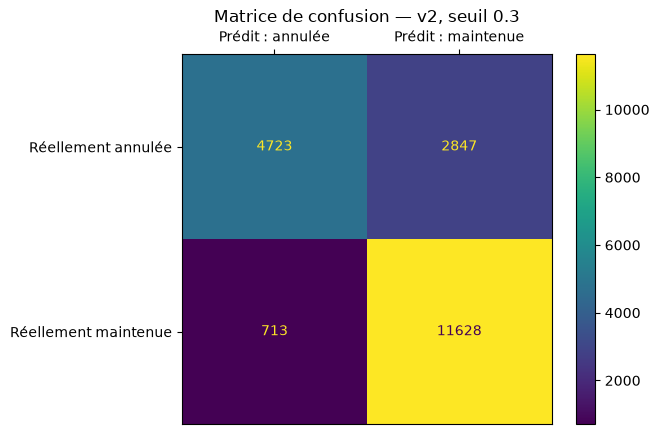

In [5]:
# Matrices de confusion sur le jeu de test (lignes : réalité, colonnes : prédiction)
for titre, modele, colonnes in [("v1", v1, V1_FEATURES), (f"v2, seuil {seuil}", v2, INPUT_FEATURES)]:
    # labels=[1, 0] : la classe annulée en premier
    affichage = ConfusionMatrixDisplay.from_estimator(modele, test[colonnes], y_test, labels=[1, 0])
    ax = affichage.ax_
    ax.set_xticklabels(["Prédit : annulée", "Prédit : maintenue"])
    ax.xaxis.tick_top()   # en-têtes des colonnes en haut
    ax.set_yticklabels(["Réellement annulée", "Réellement maintenue"])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(f"Matrice de confusion — {titre}")